# Week 7 Take Home

This week has two parts. Complete **both**.

| Part | Lessons | Project |
|------|---------|---------|
| **A. Cleaning & Visualising Data** | `1-Cleaning & Visualising Data/` | Holiday weather |
| **B. Transforming & Combining Data** | `2-Transforming & Combining Data/` | GDP and life expectancy + your own World Bank project |

Data for both parts comes from the cohort database (schemas `week07` and `week08`). See `Data Access (SQL).md`.

---
# Part A: Cleaning & Visualising Data

In [5]:
# Importing Modules
%pip install requests
import pandas as pd
import requests
from datetime import datetime
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
# Load Data from cohort database (schema week07). See "Data Access (SQL).md".
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

london = run_query("SELECT * FROM week07.london_2014")

### Solve `1-Cleaning & Visualising Data/1.ipynb` Tasks Below

In [7]:
# TASK ONE
# write code to select all days that had a northerly wind. 

# removes extra spaces from the beginning and end of every column name in the london DataFrame 
london.columns = london.columns.str.strip()

# remove the line break at the end of the WindDirDegrees column
london = london.rename(columns={'WindDirDegrees<br />' : 'WindDirDegrees'})
london['WindDirDegrees'] = london['WindDirDegrees'].str.rstrip('<br />')

# Change the datatype from string to integer, to be able to 
london['WindDirDegrees'] = london['WindDirDegrees'].astype('int64')

# All days that had a northerly wind ( where the direction is greater than or equal to 350 or smaller than or equal to 10)
london[(london['WindDirDegrees'] >= 350) | (london['WindDirDegrees'] == 10)]

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees
100,2014-4-11,16,12,9,5,4,2,71,53,28,...,31,18,10,13,8,NaN,0.00,1.0,NaN,351
110,2014-4-21,19,12,5,11,8,4,100,78,31,...,26,7,0,14,6,NaN,9.91,3.0,Fog-Rain-Thunderstorm,356
174,2014-6-24,24,19,13,15,12,9,94,66,27,...,31,12,0,23,8,37.0,0.00,3.0,Fog,350
249,2014-9-7,21,17,13,14,12,8,94,71,41,...,23,10,2,11,6,NaN,0.00,4.0,NaN,354
250,2014-9-8,22,16,10,13,9,7,94,64,28,...,27,12,5,11,6,NaN,0.00,1.0,NaN,351
335,2014-12-2,8,7,6,7,4,2,100,80,62,...,31,11,1,27,13,NaN,1.02,5.0,Rain,359


In [8]:
# TASK 2
# convert GMT, from str to datetime datatype
london['GMT'] = pd.to_datetime(london['GMT'])

# display all the rows in the dataframe that are beween 1 April 2014 and 11 April 2014.
dates = london['GMT']
start = datetime(2014, 12, 1)
end = datetime(2014, 12, 11)
london[(dates >= start) & (dates <= end)]

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees
334,2014-12-01,8,7,6,8,4,3,93,80,67,...,26,9,6,16,13,NaN,0.00,7.0,Rain,33
335,2014-12-02,8,7,6,7,4,2,100,80,62,...,31,11,1,27,13,NaN,1.02,5.0,Rain,359
336,2014-12-03,8,6,4,5,3,1,93,78,56,...,31,15,9,23,16,37.0,0.51,4.0,Rain,17
337,2014-12-04,5,4,3,4,3,0,100,87,61,...,16,8,2,23,10,NaN,4.06,6.0,Rain,52
338,2014-12-05,7,4,2,4,3,0,100,87,72,...,31,10,5,14,6,NaN,0.00,4.0,Rain,293
339,2014-12-06,6,2,-1,3,1,-1,100,85,60,...,31,15,10,14,8,NaN,0.25,4.0,NaN,265
340,2014-12-07,11,7,2,8,4,-1,93,79,47,...,31,14,10,35,16,NaN,0.51,3.0,Rain,246
341,2014-12-08,7,4,1,2,1,-1,93,76,51,...,31,17,10,23,13,NaN,0.00,2.0,Rain,270
342,2014-12-09,12,6,-1,11,3,-1,100,86,64,...,31,15,3,37,14,52.0,0.25,5.0,Rain,224
343,2014-12-10,9,7,6,11,3,1,90,70,44,...,31,18,3,40,27,NaN,0.00,2.0,Rain,246


In [5]:
# TASK 3
# display the first five rows that have a missing value in the 'Max Gust SpeedKm/h' column

missing_value = london[london['Max Gust SpeedKm/h'].isnull()]
missing_value.head()

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees
4,2014-01-05,12,7,1,11,4,-1,100,88,77,...,31,14,5,35,16,NaN,0.25,5.0,Rain,199
10,2014-01-11,9,4,0,7,3,-1,100,80,51,...,31,12,6,24,14,NaN,0.00,4.0,Rain,259
11,2014-01-12,10,4,-2,9,3,-2,100,91,79,...,31,9,1,32,10,NaN,0.51,6.0,Fog-Rain,126
12,2014-01-13,9,7,5,8,4,3,93,85,71,...,31,16,5,34,19,NaN,5.08,2.0,Rain,205
13,2014-01-14,7,4,1,5,2,0,100,82,55,...,31,15,10,21,13,NaN,0.25,3.0,Rain,242


### Solve `1-Cleaning & Visualising Data/2.ipynb` Tasks Below

<Axes: xlabel='GMT'>

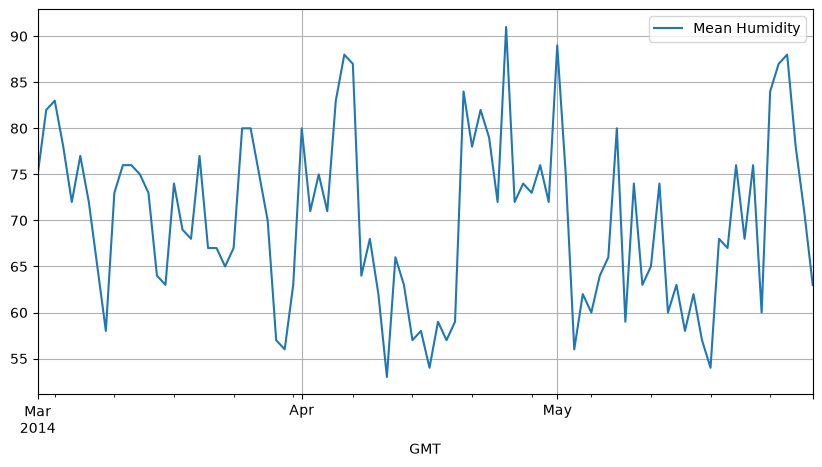

In [6]:
# plot the values of 'Mean Humidity' during spring (full months of March, April and May).

london.index = london['GMT']

london.loc[datetime(2014, 3, 1) : datetime(2014, 5, 31), ['Mean Humidity']].plot(grid=True, figsize=(10, 5))

## Project A: Holiday weather


There is nothing I like better than taking a holiday. In this project I am going to use the historic weather data from the Weather Underground for London to try to predict two good weather weeks to take off as holiday. Of course the weather in the summer of 2025 may be very different to 2020 but it should give some indication of when would be a good time to take a summer break.

## Getting the data

Weather Underground keeps historical weather data collected in many airports around the world. Right-click on the following URL and choose 'Open Link in New Window' (or similar, depending on your browser):

http://www.wunderground.com/history

When the new page opens start typing 'LHR' in the 'Location' input box and when the pop up menu comes up with the option 'LHR, United Kingdom' select it and then click on 'Submit'. 

When the next page opens with London Heathrow data, click on the 'Custom' tab and select the time period From: 1 January 2023 to: 31 December 2023 and then click on 'Get History'. The data for that year should then be displayed further down the page. 

You can copy each month's data directly from the browser to a text editor like Notepad or TextEdit, to obtain a single file with as many months as you wish.


Now load the CSV file into a dataframe making sure that any extra spaces are skipped:

### Step-1 Cleaning the data


In [7]:
# Load the csv into dataframe
# Temperature, Dew point, are measured in degree ferenheit
df = pd.read_csv("LHR_2023_Weather_Data.csv", encoding="cp1252", skipinitialspace=True)
df.columns

Index(['Date', 'Max_Temperature', 'Avg_Temperature', 'Min_Temperature',
       'Max_Dew_Point', 'Avg_Dew_Point', 'Min_Dew_Point', 'Max_Humidity',
       'Avg_Humidity', 'Min_Humidity', 'Max_Wind_Speed', 'Avg_Wind_Speed',
       'Min_Wind_Speed', 'Max_Pressure', 'Avg_Pressure', 'Min_Pressure',
       'Total_Precipitation'],
      dtype='str')

In [8]:
df.head(3)

,Date,Max_Temperature,Avg_Temperature,Min_Temperature,Max_Dew_Point,Avg_Dew_Point,Min_Dew_Point,Max_Humidity,Avg_Humidity,Min_Humidity,Max_Wind_Speed,Avg_Wind_Speed,Min_Wind_Speed,Max_Pressure,Avg_Pressure,Min_Pressure,Total_Precipitation
0,1/1/2023,54,51.1,45,48,44.9,43,93,79.6,71,20,11.9,2,29.7,29.7,29.5,0
1,1/2/2023,46,42.8,36,43,39.1,34,100,87.0,70,12,6.6,1,30.1,29.9,29.7,0
2,1/3/2023,55,47.1,36,52,44.8,34,100,92.3,87,21,11.7,0,30.1,30.0,29.8,0


In [9]:
# To check if there are null values(Although i already know they are no null values because i collated the data)
df.isnull().sum()

Date                   0
Max_Temperature        0
Avg_Temperature        0
Min_Temperature        0
Max_Dew_Point          0
Avg_Dew_Point          0
Min_Dew_Point          0
Max_Humidity           0
Avg_Humidity           0
Min_Humidity           0
Max_Wind_Speed         0
Avg_Wind_Speed         0
Min_Wind_Speed         0
Max_Pressure           0
Avg_Pressure           0
Min_Pressure           0
Total_Precipitation    0
dtype: int64

In [10]:
# To check and change datatype if neccessary

df.dtypes

Date                       str
Max_Temperature          int64
Avg_Temperature        float64
Min_Temperature          int64
Max_Dew_Point            int64
Avg_Dew_Point          float64
Min_Dew_Point            int64
Max_Humidity             int64
Avg_Humidity           float64
Min_Humidity             int64
Max_Wind_Speed           int64
Avg_Wind_Speed         float64
Min_Wind_Speed           int64
Max_Pressure           float64
Avg_Pressure           float64
Min_Pressure           float64
Total_Precipitation      int64
dtype: object

In [11]:
# The Date datatype is saved as string, so we will convert to datetime
df['Date'] = pd.to_datetime(df['Date'])
df['Date'].head(3)

0   2023-01-01
1   2023-01-02
2   2023-01-03
Name: Date, dtype: datetime64[us]

### Step-2 Finding a summer break

According to meteorologists, summer extends for the whole months of June, July, and August in the northern hemisphere and the whole months of December, January, and February in the southern hemisphere. So create a dataframe that holds just those months using the `datetime` index.

In [12]:
# Creating a dataframe for the different Hemisphere using datetime index
df = df.set_index("Date")

# Northern Hemisphere
northern_summer = df.loc["2023-06-01" : "2023-08-31"]
northern_summer.head()

,Max_Temperature,Avg_Temperature,Min_Temperature,Max_Dew_Point,Avg_Dew_Point,Min_Dew_Point,Max_Humidity,Avg_Humidity,Min_Humidity,Max_Wind_Speed,Avg_Wind_Speed,Min_Wind_Speed,Max_Pressure,Avg_Pressure,Min_Pressure,Total_Precipitation
Date,,,,,,,,,,,,,,,,
2023-06-01,66,56.0,50,48,45.9,43,87,70.0,49,13,9.8,8,30.2,30.2,30.1,0
2023-06-02,66,56.9,50,45,42.5,39,76,59.3,43,13,10.3,8,30.2,30.2,30.1,0
2023-06-03,72,59.1,46,50,46.3,41,87,64.9,41,13,8.7,3,30.1,30.1,30.1,0
2023-06-04,73,61.1,50,50,45.4,41,82,58.5,36,12,8.4,3,30.2,30.1,30.1,0
2023-06-05,64,56.1,50,46,45.0,43,82,67.0,52,12,9.2,7,30.2,30.2,30.1,0


In [13]:
# Southern Hemisphere

southern_summer = df.loc["2023-06-01" : "2023-08-31"]
southern_summer.head()

,Max_Temperature,Avg_Temperature,Min_Temperature,Max_Dew_Point,Avg_Dew_Point,Min_Dew_Point,Max_Humidity,Avg_Humidity,Min_Humidity,Max_Wind_Speed,Avg_Wind_Speed,Min_Wind_Speed,Max_Pressure,Avg_Pressure,Min_Pressure,Total_Precipitation
Date,,,,,,,,,,,,,,,,
2023-06-01,66,56.0,50,48,45.9,43,87,70.0,49,13,9.8,8,30.2,30.2,30.1,0
2023-06-02,66,56.9,50,45,42.5,39,76,59.3,43,13,10.3,8,30.2,30.2,30.1,0
2023-06-03,72,59.1,46,50,46.3,41,87,64.9,41,13,8.7,3,30.1,30.1,30.1,0
2023-06-04,73,61.1,50,50,45.4,41,82,58.5,36,12,8.4,3,30.2,30.1,30.1,0
2023-06-05,64,56.1,50,46,45.0,43,82,67.0,52,12,9.2,7,30.2,30.2,30.1,0


In [14]:
# Creating a table that holds both data from northern and southern hemisphere

summer_data = pd.concat([northern_summer, southern_summer])
summer_data.head()

,Max_Temperature,Avg_Temperature,Min_Temperature,Max_Dew_Point,Avg_Dew_Point,Min_Dew_Point,Max_Humidity,Avg_Humidity,Min_Humidity,Max_Wind_Speed,Avg_Wind_Speed,Min_Wind_Speed,Max_Pressure,Avg_Pressure,Min_Pressure,Total_Precipitation
Date,,,,,,,,,,,,,,,,
2023-06-01,66,56.0,50,48,45.9,43,87,70.0,49,13,9.8,8,30.2,30.2,30.1,0
2023-06-02,66,56.9,50,45,42.5,39,76,59.3,43,13,10.3,8,30.2,30.2,30.1,0
2023-06-03,72,59.1,46,50,46.3,41,87,64.9,41,13,8.7,3,30.1,30.1,30.1,0
2023-06-04,73,61.1,50,50,45.4,41,82,58.5,36,12,8.4,3,30.2,30.1,30.1,0
2023-06-05,64,56.1,50,46,45.0,43,82,67.0,52,12,9.2,7,30.2,30.2,30.1,0


---
# Part B: Transforming & Combining Data

### Provide `2-Transforming & Combining Data/1.ipynb` Tasks Solutions below (Execute them)

In [15]:
#  TASK ONE
#  Create your population dataframe 'Country name', 'Life expectancy (years)'
#  Although I feel like this is a mistake, because this table is meant to hold population data, not life expectancy. But since it is explicitly started in the task, I will create it as requested.
headings = ['Country name', 'Life expectancy (years)']
table = [
  ['Japan', 84],
  ['London', 82],
  ['France', 81],
  ['China', 75],
  ['Russia', 71],
  ['United States', 79],
  ['India', 66],
  ['United Kingdom', 81],
  ['Nigeria', 50]
]
population = pd.DataFrame(columns=headings, data=table)

In [18]:
# TASK TWO
# Join your population dataframe previous task with gdpVsLife, in four different ways, and note the differences.

# To do this, I will have to create the gdpVsLife data frame

# Firstly, i will create a gdp dataframe

table = [
  ['UK', 2678454886796.7],
  ['USA', 16768100000000.0],
  ['China', 9240270452047.0],
  ['Brazil', 2245673032353.8],
  ['South Africa', 366057913367.1],
  ['Canada', 184620945320.1],
  ['Australia', 24123456211.0],
  ['Nigeria', 13276842.0]

]
headings = ['Country', 'GDP (US$)']
gdp = pd.DataFrame(columns=headings, data=table)

# Secondly, I will create a dataframe for life expectancy

headings = ['Country name', 'Life expectancy (years)']
table = [
  ['China', 75],
  ['Russia', 71],
  ['United States', 79],
  ['India', 66],
  ['United Kingdom', 81],
  ['Germany', 80],
  ['Ghana', 82],
  ['Nigeria', 50],
]
life = pd.DataFrame(columns=headings, data=table)

# Define some constants to be used in the merge
def roundToMillions (value):
    return round(value / 1000000)

def usdToGBP (usd):
    return usd / 1.564768 # average rate during 2013

def expandCountry (name):
    if name == 'UK':
        name = 'United Kingdom'
    if name == 'USA':
        name = 'United States'
    return name

In [17]:

# Thirdly, I will do a little bit of cleaning

gdp['Country name'] = gdp['Country'].apply(expandCountry)
gdp['GDP (£m)'] = gdp['GDP (US$)'].apply(usdToGBP).apply(roundToMillions)
gdp['GDP (US$)'].apply(roundToMillions).apply(usdToGBP).apply(round)
headings = ['Country name', 'GDP (£m)']
gdp = gdp[headings]

# Fourthly, I will have to join the 2 tables to get gdpVsLife
# I will use inner join, so I can get only values in both tables.

gdpVsLife = pd.merge(gdp, life, on='Country name', how='inner')
print(gdpVsLife)

# Now that we have gdpVsLife, I will have to join the data using the 4 different methods.
# inner join
merged_inner = pd.merge(population, gdpVsLife, on="Country name", how="inner")
print(f"Inner join table: \n {merged_inner}")

# Outer Join
merged_outer = pd.merge(population, gdpVsLife, on="Country name", how="outer")
print(f"Outer join table: \n {merged_outer}")

# Right Join
merged_right = pd.merge(population, gdpVsLife, on="Country name", how="right")
print(f"Right join table: \n {merged_right}")

# Left Join
merged_left = pd.merge(population, gdpVsLife, on="Country name", how="left")
print(f"Left join table: \n {merged_right}")

     Country name  GDP (£m)  Life expectancy (years)
0  United Kingdom   1711727                       81
1   United States  10716029                       79
2           China   5905202                       75
3         Nigeria         8                       50
Inner join table: 
      Country name  Life expectancy (years)_x  GDP (£m)  \
0           China                         75   5905202   
1   United States                         79  10716029   
2  United Kingdom                         81   1711727   
3         Nigeria                         50         8   

   Life expectancy (years)_y  
0                         75  
1                         79  
2                         81  
3                         50  
Outer join table: 
      Country name  Life expectancy (years)_x    GDP (£m)  \
0           China                         75   5905202.0   
1          France                         81         NaN   
2           India                         66         NaN   
3        

The difference between the joining are:

For inner join, only the values were the countries are present in the population and gdpVsLife dataframes were Joined together, this no missing values

For Outer join, all the countries are added, but then any column that don't have value are represented as NaN, meaning not a number.

For Left join, all the countries in the left table, being population where selected, and joined to only the columns on the gdpVsLife, which has the same countries with the population. Unavailable column data values in the left will be represented as NaN.

For right join, it's the opposite or inverse of left join.

In [19]:
# TASK THREE
# Rewrite the above codes using constants, when appropriate.
# For this, i will have to re-run the dataframes creation cells, and then use constants to rewrite the code.

GDP_USD = 'GDP (US$)'
GDP_GBP = 'GDP (£m)'
print(GDP_USD)

COUNTRY = 'Country name'
gdp[COUNTRY] = gdp['Country'].apply(expandCountry)
gdp[GDP_GBP] = gdp[GDP_USD].apply(usdToGBP).apply(roundToMillions)
headings = [COUNTRY, GDP_GBP]
gdp = gdp[headings]



gdpVsLife = pd.merge(gdp, life, on=COUNTRY, how='inner')
print(gdpVsLife)

# Now that we have gdpVsLife, I will have to join the data using the 4 different methods.
# inner join
merged_inner = pd.merge(population, gdpVsLife, on=COUNTRY, how="inner")
print(f"Inner join table: \n {merged_inner}")

# Outer Join
merged_outer = pd.merge(population, gdpVsLife, on=COUNTRY, how="outer")
print(f"Outer join table: \n {merged_outer}")

# Right Join
merged_right = pd.merge(population, gdpVsLife, on=COUNTRY, how="right")
print(f"Right join table: \n {merged_right}")

# Left Join
merged_left = pd.merge(population, gdpVsLife, on=COUNTRY, how="left")
print(f"Left join table: \n {merged_left}")

GDP (US$)
     Country name  GDP (£m)  Life expectancy (years)
0  United Kingdom   1711727                       81
1   United States  10716029                       79
2           China   5905202                       75
3         Nigeria         8                       50
Inner join table: 
      Country name  Life expectancy (years)_x  GDP (£m)  \
0           China                         75   5905202   
1   United States                         79  10716029   
2  United Kingdom                         81   1711727   
3         Nigeria                         50         8   

   Life expectancy (years)_y  
0                         75  
1                         79  
2                         81  
3                         50  
Outer join table: 
      Country name  Life expectancy (years)_x    GDP (£m)  \
0           China                         75   5905202.0   
1          France                         81         NaN   
2           India                         66         NaN   

### Provide `2-Transforming & Combining Data/2.ipynb` Tasks Solutions below (Execute them)

In [35]:
# TASK ONE
# Create a data frame with the World Bank's data on population, using the CSV file provided. 
# Since there is already a CSV file in the training database, i will use it
POPULATION_INDICATOR = 'SP.POP.TOTL'
populationReset = run_query("SELECT * FROM week08.wb_pop_2013")
populationReset.head()

,country,year,SP.POP.TOTL
0,Arab World,2013,3.770967e+08
1,Caribbean small states,2013,6.975819e+06
2,Central Europe and the Baltics,2013,1.037137e+08
3,East Asia & Pacific (all income levels),2013,2.248867e+09
4,East Asia & Pacific (developing only),2013,2.006073e+09


In [36]:
# TASK TWO
# Clean the population dataframe you created in the previous task.

# Remove aggregate rows, and keep only the rows that have a country name and a population value.
populationCountries = populationReset[34:]

# Remove rows with missing data / values
populationData = populationCountries.dropna()

# Discard year column, since it is not needed for the analysis
COUNTRY = 'country'
headings = [COUNTRY, POPULATION_INDICATOR]
populationClean = populationData[headings]


In [25]:
# Round the population values to the nearest million
populationData[POPULATION_INDICATOR] = populationData[POPULATION_INDICATOR].apply(roundToMillions)

# Rename the column for display
populationData = populationData.rename(columns={POPULATION_INDICATOR: 'Population(millions)'})

# Round to the nearest million
POPULATION = 'Population(millions)'
populationClean = populationData[['country', POPULATION]]
populationClean.head()

,country,Population(millions)
34,Afghanistan,31
35,Albania,3
36,Algeria,38
37,American Samoa,0
38,Andorra,0


In [23]:
# TASK THREE
# Merge gdpVsLife with the population dataframe obtained in the previous exercise.

# Since gdpVsLifeClean is already calculated in the example code below, i will run the code cells, and then use it to merge with the populationClean dataframe.
populationGdpVsLife = pd.merge(populationClean, gdpVsLife, on=COUNTRY, how='inner')
populationGdpVsLife.head()

,country,Population(millions),GDP (£m),Life expectancy (years)
0,Afghanistan,31,13075,60
1,Albania,3,8168,78
2,Algeria,38,134016,75
3,Angola,23,88420,52
4,Antigua and Barbuda,0,767,76


In [24]:
# TASK FOUR
# Calculate the correlation between GDP and population.

gdpColumn = gdpVsLife[GDP]
populationColumn = populationGdpVsLife[POPULATION]
(correlation, pValue) = spearmanr(gdpColumn, populationColumn)
print('The correlation is', correlation)
if pValue < 0.05:
    print('It is statistically significant.')
else:
    print('It is not statistically significant.')

The correlation is 0.7056367228611176
It is statistically significant.


<Axes: xlabel='Life expectancy (years)', ylabel='GDP (£m)'>

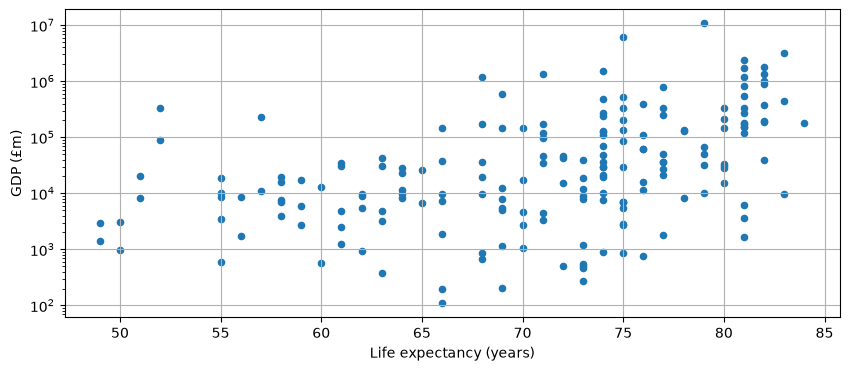

In [54]:
# TASK FIVE
# Swap the axes of the scatterplot, i.e. show the GDP in the y axis and the life expectancy in the x axis.

gdpVsLife.plot(x=LIFE, y=GDP, kind='scatter', grid=True, logy=True, figsize = (10, 4))

<Axes: xlabel='GDP (£m)', ylabel='Population(millions)'>

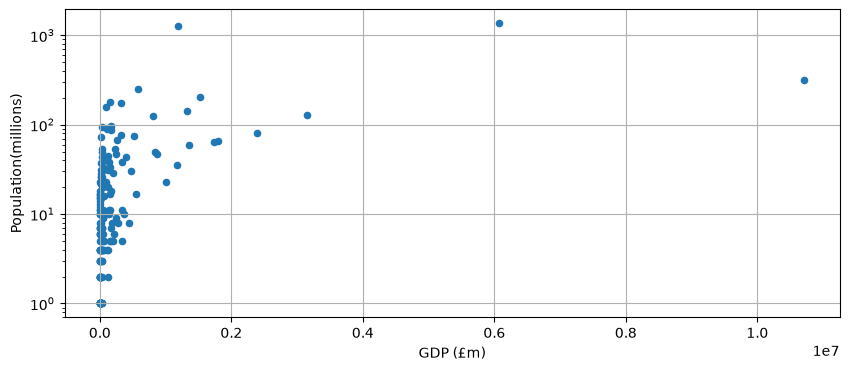

In [55]:
# Display a scatterplot of the GDP and the population.

populationGdpVsLife.plot(x=GDP, y=POPULATION, kind='scatter', grid=True, logy=True, figsize = (10, 4))

### Provide `2-Transforming & Combining Data/2.ipynb` Assignment Solutions below (Execute them)

# Extend the project
Answer the following questions: 

1) To what extent do the ten countries with the highest GDP coincide with the ten countries with the longest life expectancy?

2) Which are the two countries in the right half of the plot (higher GDP) with life expectancy below 60 years?

3) What factors could explain their lower life expectancy compared to countries with similar GDP? Hint: use the filtering techniques you learned in Week 2 to find the two countries.

4) Redo the analysis using the countries’ GDP per capita (i.e. per inhabitant) instead of their total GDP. If you’ve done the workbook task, you already have a column with the population data.

In [17]:
#  ASSIGNMENT ONE
# Top 10 countries by GDP
top_gdp = gdpVsLife.sort_values(GDP).tail(10)

# Top 10 countries by life expectancy
top_life = gdpVsLife.sort_values(LIFE).tail(10)

# Countries appearing in both groups
common = set(top_gdp[COUNTRY]) & set(top_life[COUNTRY])

print(common)
print("Number of countries in common:", len(common))

{'Japan', 'France', 'Italy'}
Number of countries in common: 3


Three countries: Japan, Italy, and France — appearred in both table.
This means that 3 out of the top 10 countries (30%) overlaps. The result suggests that high economic output can coincide with high life expectancy. However, the other seven countries in each group do not overlap, showing that having a high total GDP does not automatically guarantee a long life expectancy. Other factors, such as healthcare quality, living conditions, nutrition, and access to medical services, can also influence how long people live.

In [31]:
# ASSIGNMENT TWO
# Countries at the right of the plot (with higher GDP) and life expectancy below 60 years

median_gdp = gdpVsLife[GDP].median()

gdpVsLife[
    (gdpVsLife[GDP] > median_gdp) &
    (gdpVsLife[LIFE] < 60)
]

,country,GDP (£m),Life expectancy (years)
3,Angola,88420,52
124,Nigeria,329100,52
152,South Africa,234056,57


These findings show that a relatively high total GDP does not necessarily correspond to high life expectancy. Nigeria and South Africa have substantially higher total GDP than Angola, yet all three countries have life expectancy below 60 years. This suggests that total economic output alone does not reflect how wealth is distributed or whether people have adequate access to healthcare and other essential services.

In [33]:
# ASSIGNMENT THREE

# Since we have gotten countries with high GDP, and low life expectancy, lets get the opposite, and then compare
# Countries with higher GDP and life expectancy of at least 60 years
gdpVsLife[
    (gdpVsLife[GDP] > gdpVsLife[GDP].median()) &
    (gdpVsLife[LIFE] >= 60)
].sort_values(GDP)

,country,GDP (£m),Life expectancy (years)
84,Jordan,21469,74
183,"Yemen, Rep.",22978,64
172,Turkmenistan,26210,65
128,Panama,27255,77
94,Lebanon,28344,80
...,...,...,...
58,France,1795953,82
62,Germany,2393529,81
83,Japan,3143957,83
35,China,6065182,75


Nigeria and South Africa have life expectancies below 60 years despite being in the higher-GDP group. In contrast, countries such as France and Japan have life expectancies above 80 years. This suggests that total GDP alone does not determine life expectancy. Differences in healthcare access, poverty, sanitation, maternal and child mortality, nutrition, and infectious disease burden may contribute to the gap, but further data would be needed to establish which factors explain it in these countries.

In [ ]:
# ASSIGNMENT FOUR
# Redo the analysis.
# Calculate GDP per capita
# i have to convert the population to millions, because rounding off to millions gave me zero vales that lead to division by zero error.
populationData[POPULATION_INDICATOR] = populationData[POPULATION_INDICATOR] / 1000000
POPULATION = POPULATION_INDICATOR

populationClean = populationData[['country', POPULATION]]

populationGdpVsLife = pd.merge(populationClean, gdpVsLife, on=COUNTRY, how='inner')

populationGdpVsLife['GDP per capita'] = (
    populationGdpVsLife[GDP] / populationGdpVsLife[POPULATION]
).round()
populationGdpVsLife.head(5)


,country,SP.POP.TOTL,GDP (£m),Life expectancy (years),GDP per capita
0,Afghanistan,3.068250e-11,13075,60,4.261387e+14
1,Albania,2.897366e-12,8168,78,2.819112e+15
2,Algeria,3.818613e-11,134016,75,3.509546e+15
3,Angola,2.344820e-11,88420,52,3.770865e+15
4,Antigua and Barbuda,8.998500e-14,767,76,8.523643e+15


In [40]:
# Top 10 countries with the highest GDP per capita
top_gdp_per_capita = populationGdpVsLife.sort_values('GDP per capita').tail(10)

top_gdp_per_capita[[COUNTRY, 'GDP per capita', LIFE]]

,country,GDP per capita,Life expectancy (years)
147,Singapore,3.577511e+16,82
46,Denmark,3.822842e+16,80
161,Sweden,3.852535e+16,82
7,Australia,4.321905e+16,82
162,Switzerland,5.410981e+16,83
18,Bermuda,5.479916e+16,81
100,"Macao SAR, China",5.772846e+16,80
136,Qatar,6.139996e+16,78
125,Norway,6.571728e+16,81
99,Luxembourg,7.267926e+16,82


In [42]:
# Calculate the correlation between GDP per capita and LIFE.

gdpColumn = populationGdpVsLife['GDP per capita']
lifeColumn = populationGdpVsLife[LIFE]
(correlation, pValue) = spearmanr(gdpColumn, lifeColumn)
print('The correlation is', correlation)
if pValue < 0.05:
    print('It is statistically significant.')
else:
    print('It is not statistically significant.')

The correlation is 0.8503040098920375
It is statistically significant.


<Axes: xlabel='GDP per capita', ylabel='Life expectancy (years)'>

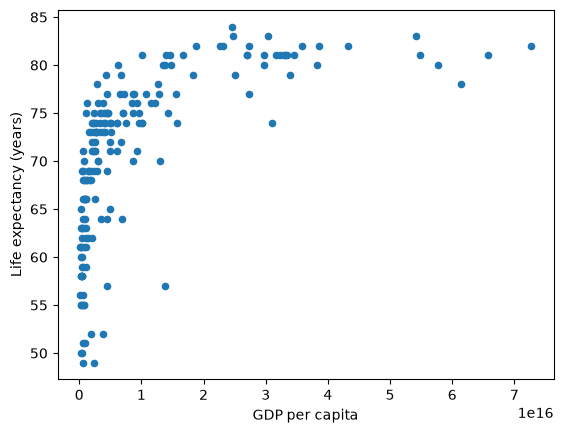

In [43]:
# Scatterplot of GDP per capita and life expectancy
populationGdpVsLife.plot(
    kind='scatter',
    x='GDP per capita',
    y=LIFE
)

GDP per capita has a strong positive correlation with life expectancy (p_value = 0.85). This suggests that countries with higher GDP per inhabitant tend to have higher life expectancy. The relationship is statistically significant.

### Read and follow the below example analysis

## Project B: GDP and life expectancy

Richer countries can afford to invest more on healthcare, on work and road safety, and other measures that reduce mortality. On the other hand, richer countries may have less healthy lifestyles. Is there any relation between the wealth of a country and the life expectancy of its inhabitants?

The following analysis checks whether there is any correlation between the total gross domestic product (GDP) of a country in 2013 and the life expectancy of people born in that country in 2013.

## Getting the data

Two datasets of the World Bank are considered. One dataset, available at <http://data.worldbank.org/indicator/NY.GDP.MKTP.CD>, lists the GDP of the world's countries in current US dollars, for various years. The use of a common currency allows us to compare GDP values across countries. The other dataset, available at <http://data.worldbank.org/indicator/SP.DYN.LE00.IN>, lists the life expectancy of the world's countries. The datasets were downloaded as CSV files in March 2016.

In [11]:
import warnings
warnings.simplefilter('ignore', FutureWarning)

import pandas as pd

# Load Data from cohort database (schema week08). See "Data Access (SQL).md".
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

YEAR = 2013
GDP_INDICATOR = 'NY.GDP.MKTP.CD'
gdpReset = run_query("SELECT * FROM week08.wb_gdp_2013")

LIFE_INDICATOR = 'SP.DYN.LE00.IN'
lifeReset = run_query("SELECT * FROM week08.wb_le_2013")
lifeReset.head()


,country,year,SP.DYN.LE00.IN
0,Arab World,2013,70.631305
1,Caribbean small states,2013,71.901964
2,Central Europe and the Baltics,2013,76.127583
3,East Asia & Pacific (all income levels),2013,74.604619
4,East Asia & Pacific (developing only),2013,73.657617


## Cleaning the data

Inspecting the data with `head()` and `tail()` shows that:

1. the first 34 rows are aggregated data, for the Arab World, the Caribbean small states, and other country groups used by the World Bank;
- GDP and life expectancy values are missing for some countries.

The data is therefore cleaned by:
1. removing the first 34 rows;
- removing rows with unavailable values.

In [12]:
gdpCountries = gdpReset[34:].dropna()
lifeCountries = lifeReset[34:].dropna()

## Transforming the data

The World Bank reports GDP in US dollars and cents. To make the data easier to read, the GDP is converted to millions of British pounds (the author's local currency) with the following auxiliary functions, using the average 2013 dollar-to-pound conversion rate provided by <http://www.ukforex.co.uk/forex-tools/historical-rate-tools/yearly-average-rates>. 

In [13]:
def roundToMillions (value):
    return round(value / 1000000)

def usdToGBP (usd):
    return usd / 1.564768

GDP = 'GDP (£m)'
gdpCountries[GDP] = gdpCountries[GDP_INDICATOR].apply(usdToGBP).apply(roundToMillions)
gdpCountries.head()

,country,year,NY.GDP.MKTP.CD,GDP (£m)
34,Afghanistan,2013,2.045894e+10,13075
35,Albania,2013,1.278103e+10,8168
36,Algeria,2013,2.097035e+11,134016
38,Andorra,2013,3.249101e+09,2076
39,Angola,2013,1.383568e+11,88420


The unnecessary columns can be dropped.

In [14]:
COUNTRY = 'country'
headings = [COUNTRY, GDP]
gdpClean = gdpCountries[headings]
gdpClean.head()

,country,GDP (£m)
34,Afghanistan,13075
35,Albania,8168
36,Algeria,134016
38,Andorra,2076
39,Angola,88420


The World Bank reports the life expectancy with several decimal places. After rounding, the original column is discarded.

In [15]:
LIFE = 'Life expectancy (years)'
lifeCountries[LIFE] = lifeCountries[LIFE_INDICATOR].apply(round)
headings = [COUNTRY, LIFE]
lifeClean = lifeCountries[headings]
lifeClean.head()

,country,Life expectancy (years)
34,Afghanistan,60
35,Albania,78
36,Algeria,75
39,Angola,52
40,Antigua and Barbuda,76


## Combining the data

The tables are combined through an inner join on the common 'country' column. 

In [16]:
gdpVsLife = pd.merge(gdpClean, lifeClean, on=COUNTRY, how='inner')
gdpVsLife.head()

,country,GDP (£m),Life expectancy (years)
0,Afghanistan,13075,60
1,Albania,8168,78
2,Algeria,134016,75
3,Angola,88420,52
4,Antigua and Barbuda,767,76


## Calculating the correlation

To measure if the life expectancy and the GDP grow together, the Spearman rank correlation coefficient is used. It is a number from -1 (perfect inverse rank correlation: if one indicator increases, the other decreases) to 1 (perfect direct rank correlation: if one indicator increases, so does the other), with 0 meaning there is no rank correlation. A perfect correlation doesn't imply any cause-effect relation between the two indicators. A p-value below 0.05 means the correlation is statistically significant.

In [14]:

gdpColumn = gdpVsLife[GDP]
lifeColumn = gdpVsLife[LIFE]
(correlation, pValue) = spearmanr(gdpColumn, lifeColumn)
print('The correlation is', correlation)
if pValue < 0.05:
    print('It is statistically significant.')
else:
    print('It is not statistically significant.')

The correlation is 0.5010232389671027
It is statistically significant.


The value shows a direct correlation, i.e. richer countries tend to have longer life expectancy, but it is not very strong.

## Showing the data

Measures of correlation can be misleading, so it is best to see the overall picture with a scatterplot. The GDP axis uses a logarithmic scale to better display the vast range of GDP values, from a few million to several billion (million of million) pounds.

<Axes: xlabel='GDP (£m)', ylabel='Life expectancy (years)'>

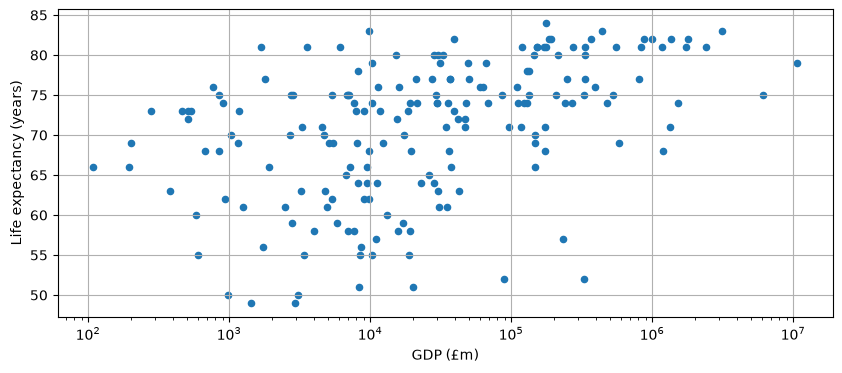

In [42]:
%matplotlib inline
gdpVsLife.plot(x=GDP, y=LIFE, kind='scatter', grid=True, logx=True, figsize=(10, 4))

The plot shows there is no clear correlation: there are rich countries with low life expectancy, poor countries with high expectancy, and countries with around 10 thousand (10<sup>4</sup>) million pounds GDP have almost the full range of values, from below 50 to over 80 years. Towards the lower and higher end of GDP, the variation diminishes. Above 40 thousand million pounds of GDP (3rd tick mark to the right of 10<sup>4</sup>), most countries have an expectancy of 70 years or more, whilst below that threshold most countries' life expectancy is below 70 years. 

Comparing the 10 poorest countries and the 10 countries with the lowest life expectancy shows that total GDP is a rather crude measure. The population size should be taken into account for a more precise definiton of what 'poor' and 'rich' means. Furthermore, looking at the countries below, droughts and internal conflicts may also play a role in life expectancy. 

In [17]:
# the 10 countries with lowest GDP
gdpVsLife.sort_values(GDP).head(10)

,country,GDP (£m),Life expectancy (years)
87,Kiribati,108,66
141,Sao Tome and Principe,195,66
111,"Micronesia, Fed. Sts.",202,69
168,Tonga,277,73
37,Comoros,383,63
157,St. Vincent and the Grenadines,461,73
140,Samoa,509,73
180,Vanuatu,512,72
65,Grenada,538,73
60,"Gambia, The",578,60


In [18]:
# the 10 countries with lowest life expectancy
gdpVsLife.sort_values(LIFE).head(10)

,country,GDP (£m),Life expectancy (years)
95,Lesotho,1418,49
160,Swaziland,2916,49
32,Central African Republic,983,50
146,Sierra Leone,3092,50
33,Chad,8276,51
41,Cote d'Ivoire,19998,51
3,Angola,88420,52
124,Nigeria,329100,52
30,Cameroon,18896,55
153,South Sudan,8473,55


## Conclusions

To sum up, there is no strong correlation between a country's wealth and the life expectancy of its inhabitants: there is often a wide variation of life expectancy for countries with similar GDP, countries with the lowest life expectancy are not the poorest countries, and countries with the highest expectancy are not the richest countries. Nevertheless there is some relationship, because the vast majority of countries with a life expectancy below 70 years is on the left half of the scatterplot.

Using the [NY.GDP.PCAP.PP.CD](http://data.worldbank.org/indicator/NY.GDP.PCAP.PP.CD) indicator, GDP per capita in current 'international dollars', would make for a better like-for-like comparison between countries, because it would take population and purchasing power into account. Using more specific data, like expediture on health, could also lead to a better analysis.

### Assessment - NOW IS YOUR TURN

**Create your own project**
Create a completely new project and choose another two of the
hundreds of World Bank indicators and see if there is any correlation between them. If
there is a choice of similar indicators, choose one that leads to meaningful
comparisons between countries.

Look at the results you obtained and take a few moments to assess how they differ.


## GOOD LUCK!

In [29]:
## So for my project, I will be working on the research question "Is undernourishment associated with tuberculosis incidence across countries in 2023?"


# Firstly, I will Retrieve the tuberculosis data using API data retrieval method
url = "https://api.worldbank.org/v2/country/all/indicator/SH.TBS.INCD"

response = requests.get(
    url,
    params={"format": "json", "date": "2023", "per_page": 1000}
)

result = response.json()

print("Total records:", result[0]["total"])
print("Pages:", result[0]["pages"])


# Create a DataFrame
tuberculosis = pd.DataFrame([
    {
        "country": item["country"]["value"],
        "code": item["countryiso3code"],
        "tb_incidence": item["value"]
    }
    for item in result[1]
])

print("Records returned:", len(tuberculosis))
print("Non-missing TB values:", tuberculosis["tb_incidence"].notna().sum())
print("Missing TB values:", tuberculosis["tb_incidence"].isna().sum())

print(tuberculosis[tuberculosis["tb_incidence"].notna()].head(10))

Total records: 266
Pages: 1
Records returned: 266
Non-missing TB values: 227
Missing TB values: 39
                                              country code  tb_incidence
6                                 East Asia & Pacific  EAS         146.0
7         East Asia & Pacific (excluding high income)  EAP         160.0
10                              Europe & Central Asia  ECS          23.0
11      Europe & Central Asia (excluding high income)  ECA          44.0
16                                        High income               13.0
23                          Latin America & Caribbean  LCN          50.0
24  Latin America & Caribbean (excluding high income)  LAC          52.0
27                                Low & middle income  LMY         160.0
28                                         Low income              201.0
29                                Lower middle income              211.0


In [32]:
# I  noticed they are regional aggregates in the above data, which is not what I want, so I have to retrieve data that will help me distinguish.

countries = requests.get(
    "https://api.worldbank.org/v2/country",
    params={"format": "json", "per_page": 400}
).json()[1]

# Get codes for individual countries
country_codes = {
    c["id"] for c in countries
    if c["region"]["value"] != "Aggregates"
}

# Keep records of individual countries
country_df = tuberculosis[tuberculosis["code"].isin(country_codes)]

#Check and display data
print("Individual countries:", len(country_df))
print("Countries with TB data:", country_df["tb_incidence"].notna().sum())

print(
    country_df[country_df["tb_incidence"].notna()]
    .sort_values("country")
    .to_string(index=False)
)

Individual countries: 217
Countries with TB data: 208
                       country code  tb_incidence
                   Afghanistan  AFG        204.00
                       Albania  ALB         15.00
                       Algeria  DZA         55.00
                American Samoa  ASM          3.90
                       Andorra  AND          4.90
                        Angola  AGO        383.00
           Antigua and Barbuda  ATG          1.10
                     Argentina  ARG         39.00
                       Armenia  ARM         21.00
                         Aruba  ABW          3.70
                     Australia  AUS          6.20
                       Austria  AUT          5.30
                    Azerbaijan  AZE         66.00
                  Bahamas, The  BHS          8.80
                       Bahrain  BHR         14.00
                    Bangladesh  BGD        221.00
                      Barbados  BRB          0.71
                       Belarus  BLR         19

In [33]:
# Remove all null values in the TB table
country_df = country_df.dropna(subset=["tb_incidence"]).copy()


# Converting the data to integer, to remove the unnecessary decimal
country_df["tb_incidence"] = country_df["tb_incidence"].astype(int)

In [34]:
# Now we have to retrieve the undernourishment data

url = "https://api.worldbank.org/v2/country/all/indicator/SN.ITK.DEFC.ZS"

response = requests.get(
    url,
    params={"format": "json", "date": "2023", "per_page": 1000}
)

data_under = response.json()

print("Records retrieved:", len(data_under[1]))

# Create a data frame
undernourishment = pd.DataFrame([
    {
        "country": item["country"]["value"],
        "code": item["countryiso3code"],
        "undernourished": item["value"]
    }
    for item in data_under[1]
])


print("Records returned:", len(undernourishment))
print("Non-missing under values:", undernourishment["undernourished"].notna().sum())
print("Missing under values:", undernourishment["undernourished"].isna().sum())

print(undernourishment[undernourishment["undernourished"].notna()].head(10))

Records retrieved: 266
Records returned: 266
Non-missing under values: 213
Missing under values: 53
                                       country code  undernourished
0                  Africa Eastern and Southern  AFE       26.176911
1                   Africa Western and Central  AFW       16.672837
2                                   Arab World  ARB       11.707650
3                       Caribbean small states  CSS        7.704843
4               Central Europe and the Baltics  CEB        2.500000
5                   Early-demographic dividend  EAR       10.341830
6                          East Asia & Pacific  EAS        3.521665
7  East Asia & Pacific (excluding high income)  EAP        3.620409
8   East Asia & Pacific (IDA & IBRD countries)  TEA        3.620409
9                                    Euro area  EMU        2.500000


In [35]:
# Using the already created country_codes
# This is to ensure its individual countries, not aggregates

undernourishment = undernourishment[
    undernourishment["code"].isin(country_codes)
].copy()

In [36]:
# Transforming and cleaning the undernourishment data

# Remove null values
undernourishment = undernourishment.dropna(
    subset=["undernourished"]
)

# Round up values to 3 decimal places
undernourishment["undernourished"] = (
    undernourishment["undernourished"].round(3)
)

In [37]:
# Check both DataFrames

print(undernourishment.head())
print(country_df.head())

print("Undernourishment records:", len(undernourishment))
print("TB records:", len(country_df))

        country code  undernourished
49  Afghanistan  AFG            29.7
50      Albania  ALB             5.5
51      Algeria  DZA             2.5
54       Angola  AGO            18.6
56    Argentina  ARG             3.2
           country code  tb_incidence
49     Afghanistan  AFG           204
50         Albania  ALB            15
51         Algeria  DZA            55
52  American Samoa  ASM             3
53         Andorra  AND             4
Undernourishment records: 165
TB records: 208


In [38]:
# Now, we will merge both tables
# I will use the inner merge, so that I can be able to get just countries in the 2 tables
merged_df = pd.merge(
    tuberculosis,
    undernourishment,
    on=["country", "code"],
    how="inner"
)

In [39]:
# Calculate correlation

from scipy.stats import spearmanr

correlation, p_value = spearmanr(
    merged_df["undernourished"],
    merged_df["tb_incidence"]
)

print("The correlation is", correlation)

if p_value < 0.05:
    print('It is statistically significant.')
else:
    print('It is not statistically significant.')

The correlation is 0.6727760842710814
It is statistically significant.


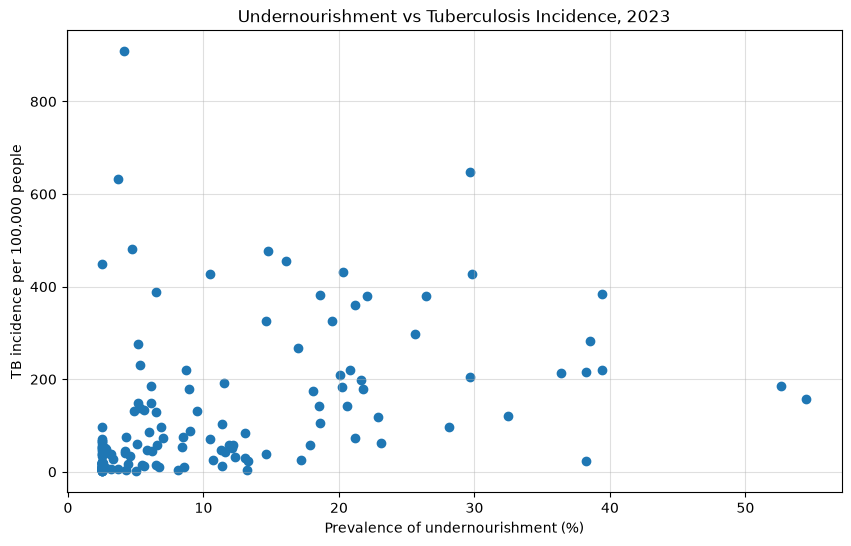

In [40]:

# Plot a scattered graph

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    merged_df["undernourished"],
    merged_df["tb_incidence"]
)

plt.xlabel("Prevalence of undernourishment (%)")
plt.ylabel("TB incidence per 100,000 people")
plt.title("Undernourishment vs Tuberculosis Incidence, 2023")
plt.grid(True, alpha=0.4)

plt.show()

In [41]:
# Check for countries and unusual values

# Check the data used in the correlation
print("Number of countries:", len(merged_df))
print("Missing values:\n", merged_df[["tb_incidence", "undernourished"]].isna().sum())

# Display countries with unusually high TB incidence
print(
    merged_df.nlargest(10, "tb_incidence")[
        ["country", "tb_incidence", "undernourished"]
    ].to_string(index=False)
)

# Check for duplicate countries
print("Duplicate country codes:", merged_df["code"].duplicated().sum())

Number of countries: 165
Missing values:
 tb_incidence      0
undernourished    0
dtype: int64
                 country  tb_incidence  undernourished
                Kiribati         908.0             4.1
        Papua New Guinea         647.0            29.7
             Philippines         632.0             3.7
                 Myanmar         482.0             4.7
                Djibouti         477.0            14.8
             Timor-Leste         455.0            16.1
                Mongolia         448.0             2.5
                 Namibia         432.0            20.3
Central African Republic         428.0            29.8
            South Africa         427.0            10.5
Duplicate country codes: 0


# Interpretation of my Results

The analysis of 165 countries in 2023 found a positive association between the prevalence of undernourishment and tuberculosis incidence (Spearman’s correlation coefficient, ρ = 0.673). The relationship was statistically significant (p < 0.05), suggesting that countries with higher levels of undernourishment tended to have higher TB incidence. However, some countries like Karibati had high TB incidence despite relatively low undernourishment, indicating that other factors may also contribute to the pattern. These findings show an association, not the actual course of the problem.

<!-- practice:start -->
---
## 🔁 SQL Practice

This week you cleaned messy weather data and combined World Bank tables in pandas. Now do the same jobs **in SQL**, straight from the raw tables: real analysts clean and combine data in the database before it ever reaches pandas.

**How it works**
1. Run the **practice setup** cell first (and again after restarting the kernel). It connects with your **read-only** account.
2. **SQL tasks:** write your query between the triple quotes and run the cell. `p.sql(...)` shows your result and
   says ✅ or ❌, and whether the **shape** (rows × columns) is right. Match the column order, sort order and rounding
   asked for (column *names* aren't checked).
3. Run `p.score()` at the end to see your practice score.

Refresh your memory with `Week-6 (Numpy & Pandas-1)/4-Intermediate SQL/Intermediate SQL.ipynb`.

In [56]:
# --- practice setup: run this cell first (don't edit it) ---
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.practice import Practice, q

EXPECTED = {
 "s01": [
  [
   1,
   1
  ],
  "1ba5edf59854386be920ac9fd3e4a2af3bb6369bf2a1aef78dcdf908c96d70a9"
 ],
 "s02": [
  [
   5,
   3
  ],
  "19042d389224a7f56403ad9636ed581989f6639acadf45b15461f55cd6258da7"
 ],
 "s03": [
  [
   10,
   3
  ],
  "e3e296058facb3595b46ac98fb75d445a82240fc775f3188d029eabc5a362ddb"
 ],
 "s04": [
  [
   1,
   1
  ],
  "ba4a24ee999caa9e01607eb78856b7212bcce521b0f6fd42d8aa90541c10382d"
 ],
 "s05": [
  [
   1,
   2
  ],
  "8153d8bbbc1b43b88ce7e4ea0c99a4ac07f4b19e0f62a9a1e04df3271f2ad3df"
 ]
}   # fingerprints only: the answers are not stored here
TITLES = {
 "s01": "Cleaning a messy column",
 "s02": "Dates: a date range",
 "s03": "Combining tables (JOIN)",
 "s04": "What gets lost in a join?",
 "s05": "Window: the driest summer week"
}
p = Practice(EXPECTED, TITLES)
print(f"Practice ready: {len(TITLES)} tasks. Connected as:", q("SELECT CURRENT_USER AS u").u[0])

Practice ready: 5 tasks. Connected as: intern_readonly


### SQL Task 1 · Cleaning a messy column

`week07.london_2014` is the **raw** export: the last column is literally named `WindDirDegrees<br />` and every
value ends in `<br />` (e.g. `'186<br />'`). Clean it **in SQL**: remove the `<br />`, convert to an integer, and
count the days when the wind direction was **greater than 350 degrees**.

**Return:** one row, one column (`days_over_350`).
💡 `REPLACE(...)`, `TRY_CAST(... AS int)`, and bracket-quote the odd column name: `[WindDirDegrees<br />]`.

In [57]:
SQL_01 = """
SELECT 
    COUNT(*) AS days_over_350
FROM week07.london_2014
WHERE TRY_CAST(REPLACE([WindDirDegrees<br />], '<br />', '') AS int) > 350;
"""
p.sql("s01", SQL_01)

,days_over_350
0,5


✅ s01: correct!


,days_over_350
0,5


### SQL Task 2 · Dates: a date range

`GMT` is stored as **text** like `'2014-1-1'`. Convert it to a real date and return London's weather for
**8–12 December 2014** (inclusive).

**Return:** `day` (a date), `Max TemperatureC`, `Min TemperatureC`, sorted by `day`.
💡 `TRY_CONVERT(date, GMT)` and `BETWEEN`.

In [58]:
SQL_02 = """
SELECT 
    TRY_CONVERT(date, GMT) AS day, 
    [Max TemperatureC], 
    [Min TemperatureC]
FROM week07.london_2014
WHERE TRY_CONVERT(date, GMT)  BETWEEN DATEFROMPARTS(2014, 12, 8) AND DATEFROMPARTS(2014, 12, 12)
ORDER BY day
"""
p.sql("s02", SQL_02)

,day,Max TemperatureC,Min TemperatureC
0,2014-12-08,7,1
1,2014-12-09,12,-1
2,2014-12-10,9,6
3,2014-12-11,10,5
4,2014-12-12,9,2


✅ s02: correct!


,day,Max TemperatureC,Min TemperatureC
0,2014-12-08,7,1
1,2014-12-09,12,-1
2,2014-12-10,9,6
3,2014-12-11,10,5
4,2014-12-12,9,2


### SQL Task 3 · Combining tables (JOIN)

Join `week08.wb_gdp_2013` and `week08.wb_le_2013` on `country`. Among entries with GDP **below 10 billion USD**
and a known life expectancy, return the **10 with the highest life expectancy**.

**Return:** `country`, `gdp_bn_usd` (GDP in billions, **rounded to 2 dp**), `life_expectancy` (**rounded to 1 dp**),
sorted by life expectancy (highest first), then `country` (A→Z) for ties.

In [71]:
SQL_03 = """
SELECT TOP 10
    g.country,
    ROUND(g.[NY.GDP.MKTP.CD] / 1000000000.0, 2) AS gdp_bn_usd,
    ROUND(l.[SP.DYN.LE00.IN], 1) AS life_expectancy
FROM week08.wb_gdp_2013 AS g
JOIN week08.wb_le_2013 AS l
    ON g.country = l.country
WHERE g.[NY.GDP.MKTP.CD] < 10000000000
    AND l.[SP.DYN.LE00.IN] IS NOT NULL
ORDER BY life_expectancy DESC, g.country ASC;
"""
p.sql("s03", SQL_03)

,country,gdp_bn_usd,life_expectancy
0,Faeroe Islands,2.61,81.3
1,Malta,9.64,80.7
2,Bermuda,5.57,80.6
3,Maldives,2.79,76.6
4,Antigua and Barbuda,1.20,75.8
5,Barbados,4.28,75.3
6,"Bahamas, The",8.43,75.1
7,St. Lucia,1.33,74.9
8,Montenegro,4.46,74.8
9,Seychelles,1.41,74.2


✅ s03: correct!


,country,gdp_bn_usd,life_expectancy
0,Faeroe Islands,2.61,81.3
1,Malta,9.64,80.7
2,Bermuda,5.57,80.6
3,Maldives,2.79,76.6
4,Antigua and Barbuda,1.20,75.8
5,Barbados,4.28,75.3
6,"Bahamas, The",8.43,75.1
7,St. Lucia,1.33,74.9
8,Montenegro,4.46,74.8
9,Seychelles,1.41,74.2


### SQL Task 4 · What gets lost in a join?

In the lesson, `dropna()` removed rows before the merge. Count what would be lost: how many rows of
`week08.wb_gdp_2013` have **no usable match**, meaning either GDP is NULL, or the life-expectancy value for that
country is NULL (or missing)?

**Return:** one row, one column (`rows_lost`).
💡 `LEFT JOIN` and test for NULLs on both sides.

In [59]:
q("SELECT * FROM week08.wb_le_2013").head(3)

,country,year,SP.DYN.LE00.IN
0,Arab World,2013,70.631305
1,Caribbean small states,2013,71.901964
2,Central Europe and the Baltics,2013,76.127583


In [78]:
SQL_04 = """
SELECT COUNT(*) AS rows_lost
FROM week08.wb_gdp_2013 AS g
LEFT JOIN week08.wb_le_2013 AS l ON g.Country = l.Country
WHERE g.[NY.GDP.MKTP.CD] IS NULL 
    OR l.[SP.DYN.LE00.IN] IS NULL
"""
p.sql("s04", SQL_04)

,rows_lost
0,29


✅ s04: correct!


,rows_lost
0,29


### SQL Task 5 · Window: the driest summer week

For the **Holiday weather** project: using London's **summer** (June, July, August 2014), find the **7-day
period with the least total rain**. A period is identified by its **start date** (that day + the next 6 days,
all inside the summer). If several periods tie, take the earliest.

**Return:** one row: `start_day` (a date), `rain_mm_7d` (**rounded to 2 dp**).
💡 `SUM(Precipitationmm) OVER (ORDER BY day ROWS BETWEEN CURRENT ROW AND 6 FOLLOWING)` in a CTE, and only keep
start days whose window has a full 7 days.

In [76]:
SQL_05 = """
WITH daily_rain AS (
    SELECT
        CAST([GMT] AS DATE) AS start_day,
        SUM(Precipitationmm) AS rain_mm
    FROM week07.london_2014
    WHERE CAST([GMT] AS DATE) >= '2014-06-01'
      AND CAST([GMT] AS DATE) < '2014-09-01'
    GROUP BY CAST([GMT] AS DATE)
),
seven_day_rain AS (
    SELECT
        start_day,
        SUM(rain_mm) OVER (
            ORDER BY start_day
            ROWS BETWEEN CURRENT ROW AND 6 FOLLOWING
        ) AS rain_mm_7d,
        ROW_NUMBER() OVER (ORDER BY start_day) AS rn
    FROM daily_rain
)
SELECT TOP 1
    start_day,
    ROUND(rain_mm_7d, 2) AS rain_mm_7d
FROM seven_day_rain
WHERE rn <= (SELECT MAX(rn) - 6 FROM seven_day_rain)
ORDER BY rain_mm_7d ASC, start_day ASC;
"""
p.sql("s05", SQL_05)

,start_day,rain_mm_7d
0,2014-06-19,0.0


✅ s05: correct!


,start_day,rain_mm_7d
0,2014-06-19,0.0


### Practice score
Run this when you're done.

In [79]:
p.score()

Task Type                          Topic Result
 s01  SQL        Cleaning a messy column      ✅
 s02  SQL            Dates: a date range      ✅
 s03  SQL        Combining tables (JOIN)      ✅
 s04  SQL      What gets lost in a join?      ✅
 s05  SQL Window: the driest summer week      ✅
SQL score: 5 / 5


,Task,Type,Topic,Result
0,s01,SQL,Cleaning a messy column,✅
1,s02,SQL,Dates: a date range,✅
2,s03,SQL,Combining tables (JOIN),✅
3,s04,SQL,What gets lost in a join?,✅
4,s05,SQL,Window: the driest summer week,✅


<!-- practice:end -->

---
## 📰 Article Link

Write a **detailed article** about this week's work. It should cover:

- **What you learnt:** the key concepts, tools and techniques from this week.
- **What you solved:** the tasks and projects you worked on, and how you approached them.
- **Challenges you faced:** what was hard, confusing or didn't work at first.
- **How you overcame them:** what you tried, what finally worked, and what you'd do differently.
- **Anything else you want to share:** insights, results, visuals, or advice for others learning this.

Publish it, then paste the article's **URL** in the empty cell below (double-click the cell to edit it).

https://medium.com/@odohmiriamnmesomafaustina/theres-more-to-data-than-meets-the-eye-my-week-7-data-cleaning-journey-20ae14ce8b76